# Описание данных

Набор данных содержит оценки степени согласия респондентов с высказываниями,
отражающими цель потребления леденцов. Всего каждый респондент выставлял оценки по 11 высказываниям:


*   V1: Я потребляю леденцы, чтобы освежить дыхание
*   V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
*   V3: Я потребляю леденцы, чтобы освежить полость рта
*   V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
*   V5: Я потребляю леденцы как заменитель других кондитерских изделий
*   V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
*   V7: Леденцы помогают мне сконцентрироваться
*   V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
*   V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
*   V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
*   V11: Я потребляю леденцы для улучшения самочувствия

In [6]:
import os
import pandas as pd
import numpy as np

In [35]:
import pandas as pd
from google.colab import files

print("Пожалуйста, загрузите файл 'Леденцы.dat'")
uploaded = files.upload()
df = pd.read_csv('Леденцы.dat', sep=';')

df.head(10)

Пожалуйста, загрузите файл 'Леденцы.dat'


Saving Леденцы.dat to Леденцы.dat


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3
5,5,4,5,5,3,3,3,3,3,3,3
6,5,5,4,5,3,3,3,3,3,3,3
7,5,4,5,5,3,3,3,3,3,3,3
8,5,5,5,5,3,3,3,3,3,3,3
9,5,4,5,4,3,3,3,3,3,3,3


In [ ]:
df.shape

(338, 11)

Посмотрим в какой шкале респонденты отвечали на вопрос.

In [ ]:
uniq=df.apply(lambda s: np.sort(s.unique()))
print(uniq)

   V1  V2  V3  V4  V5  V6  V7  V8  V9  V10  V11
0   2   2   2   2   2   2   2   2   2    2    2
1   3   3   3   3   3   3   3   3   3    3    3
2   4   4   4   4   4   4   4   4   4    4    4
3   5   5   5   5   5   5   5   5   5    5    5


Отсюда видно, что по каждому вопросу респонденты ставили от 2 до 5 "согласны ли они с утверждением". Можно предположить, что использовалась стандартная шкала оценивания - от 1 до 5.

# Кластеризация


In [13]:
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster


In [14]:
#  Кластеризуем
link = linkage(df, 'ward', 'euclidean')

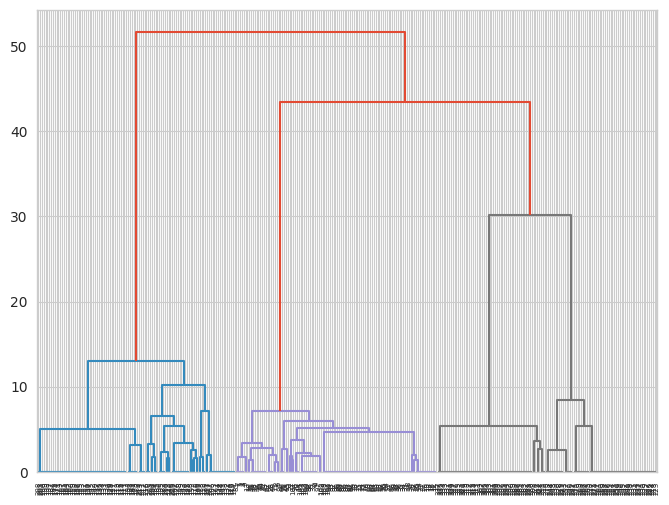

In [36]:
#первичное построение дендограммы
fig = plt.figure(figsize=(8,6))
dn = dendrogram(link, labels= df.index.tolist())

Text(0, 0.5, 'Расстояние')

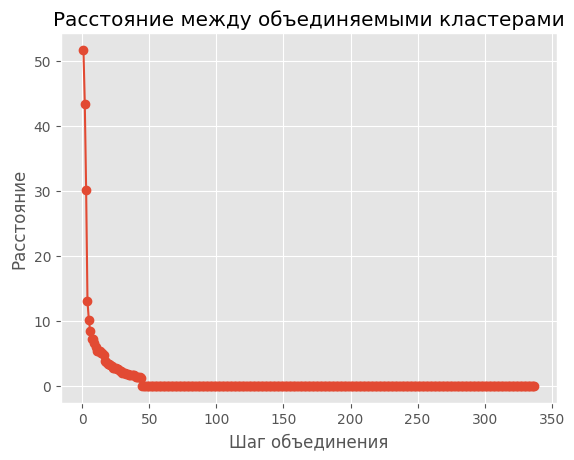

In [21]:
#построение "каменистой осыпи" для более наглядного выбора значений
dist = link[:, 2]

dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

На основе графика "каменистой осыпи" выберем значение 20, как середину интервала. Этот выбор обоснован тем, что самое "сильное" падение расстояния между объединяемыми кластерами происходит между 3-м и 4-м шагом (с ~13 до ~30).

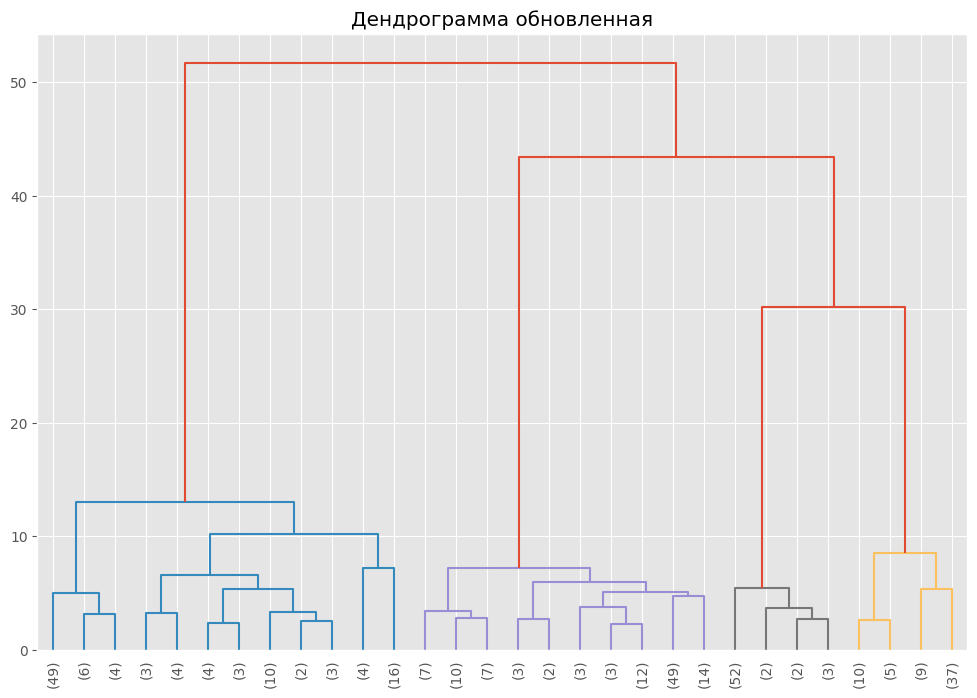

In [23]:
fig = plt.figure(figsize=(12, 8))

dn = dendrogram(
    link,
    color_threshold=20,
    labels=df.index.tolist(),
    truncate_mode='lastp', # очистка по оси x: хлопываем "кашу"
    p=30,                  # оставляем только 30 верхних веток
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title('Дендрограмма обновленная')
plt.show()

Дендограмма, постороенная с выбранным значение, также явно отображает 4.

Теперь посмотрим подробнее на то, что содержится "внутри" полученных кластеров.

In [24]:
df['cluster'] = fcluster(link, 4, criterion='maxclust')

In [25]:
df

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,cluster
0,4,5,5,5,3,3,3,3,3,3,3,2
1,5,4,5,5,3,3,3,3,3,3,3,2
2,5,5,4,5,3,3,3,3,3,3,3,2
3,5,4,5,5,3,3,3,3,3,3,3,2
4,4,5,5,5,3,3,3,3,3,3,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...
333,3,3,3,3,3,3,5,5,3,3,3,3
334,3,3,3,3,3,3,5,5,3,3,3,3
335,3,3,3,3,3,3,5,5,3,3,3,3
336,3,3,3,3,3,3,5,5,3,3,3,3


Теперь взглянем подробнее на содежание внутри каждого кластера.

In [34]:
print(df.groupby('cluster').size())

cluster
1    108
2    110
3     59
4     61
dtype: int64


In [26]:
df.groupby('cluster').mean()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000
4,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098


Обратив внимание на средние значения по каждому кластеру, можно сделать следующие выводы.

1й кластер содержит 108 наблюдений. Наиболее высокие оценки здесь респонденты дали следующим высказываниям: **V9** (облегчить боль в горле, ~4.95), **V10** (заложенность носа, ~4.81) и **V11** (улучшение самочувствия, ~4.86). Остальные показатели находятся на среднем уровне. Таким образом, можно сделать вывод, что этот сегмент потребителей, которые воспринимают леденцы в первую очередь как средство для лечения симптомов простуды.

2й кластер содержит 110 наблюдений. Здесь наиболее высоко были оценены высказывания:  **V1** (освежить дыхание, ~4.85), **V2** (уверенность, ~4.80), **V3** (освежить полость рта, ~4.84) и **V4** (избавиться от неприятного вкуса, ~4.68). То есть для потребителей этого кластера леденцы — это средство личной гигиены и поддержания уверенности в общении.

3й кластер содержит 59 наблюдений. Наиболее высокие оценки здесь респонденты дали следующим высказываниям: **V7** (помогают сконцентрироваться, ~4.92) и **V8** (отвлечься и подумать, ~4.92). Остальные значения — фоновые (около 3.0). Это сегмент потребителей, для которых леденцы - это способ снять стресс, сделать паузу в работе или сфокусироваться.

4й  кластер содержит 61 наблюдение. Здесь наиболее высоко были оценены высказывания: **V5** (заменитель кондитерских изделий, ~4.85) и **V6** (хочется сладкого, ~4.85). Можно сказать, что для этого сегмента леденцы воспринимаются как десерт и вкусное лакомство, а не средство гигиены или лекарство.

In [28]:
df[df['cluster']==1].index.values

array([110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122,
       123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135,
       136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148,
       149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161,
       162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174,
       175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187,
       188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200,
       201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213,
       214, 215, 216, 217])

# Выводы о результате работы

В ходе лабораторной работы был проведен иерархический кластерный анализ данных опроса потребителей леденцов (338 респондентов, 11 переменных).

1.  Для кластеризации использовался метод Уорда (Ward) с евклидовой метрикой. Метод Уорда минимизирует внутрикластерную дисперсию и часто используется для выделения компактных групп объектов.
2. С помощью графика «каменистой осыпи» (зависимости расстояния от шага объединения) был выявлен наиболее сильный скачок расстояния: при переходе от 4 к 3 кластерам расстояние резко возрастает (с ~13 до ~30). Это может свидетельствовать о том, что объекты внутри 4-х групп значительно ближе друг к другу, чем к объектам из соседних групп. Следовательно, оптимальным числом кластеров является **4**. Именно на этом значении я и остановилась.
3.  При установке порога threshold=20 (значение выбрано на основе результатов предыдущего шага) на дендрограмме алгоритм четко выделил 4 ветви.
4.  Данные, полученные для кластеров, можно по интерпретации полученных значений разделить на 4 четко легко обьяснимых сегмента: «Лечебный», «Свежесть дыхания», «Психологический» и «Сладкоежки».